# 20nodes_EB_obsconf4_latconf4_Gaussian_Linear: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf4_latconf4_Gaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.375366,0.087754,15
1,DAGMA_Linear,0.169114,0.049360,15
2,DAGMA_Nonlinear,0.106851,0.057187,15
3,DAS,0.105977,0.042190,15
4,DirectLiNGAM,0.268881,0.066722,15
5,FCI,0.062562,0.054086,15
6,GES,0.304107,0.084236,15
7,GOLEM,0.133543,0.066108,15
8,GRaSP,0.387895,0.073469,15
9,GraNDAG,0.049820,0.040129,15


,model,mean,std,size
0,AVICI,68.200000,15.302661,15
1,DAGMA_Linear,66.000000,5.042675,15
2,DAGMA_Nonlinear,77.871111,7.974303,15
3,DAS,115.066667,10.173261,15
4,DirectLiNGAM,135.000000,12.106669,15
5,FCI,66.302222,7.654353,15
6,GES,122.133333,15.051657,15
7,GOLEM,92.733333,8.647598,15
8,GRaSP,86.737778,13.556360,15
9,GraNDAG,57.000000,6.233550,15


,model,mean,std,size
0,AVICI,0.406182,0.117840,15
1,DAGMA_Linear,0.219330,0.069592,15
2,DAGMA_Nonlinear,0.117615,0.061272,15
3,DAS,0.082768,0.035503,15
4,DirectLiNGAM,0.183187,0.048767,15
5,FCI,0.336696,0.252855,15
6,GES,0.213680,0.064067,15
7,GOLEM,0.118207,0.061341,15
8,GRaSP,0.306186,0.067643,15
9,GraNDAG,0.348677,0.295062,15


,model,mean,std,size
0,AVICI,0.376971,0.114147,15
1,DAGMA_Linear,0.139443,0.041317,15
2,DAGMA_Nonlinear,0.099980,0.056104,15
3,DAS,0.148679,0.053466,15
4,DirectLiNGAM,0.507659,0.103529,15
5,FCI,0.034983,0.031041,15
6,GES,0.533680,0.128851,15
7,GOLEM,0.155577,0.074524,15
8,GRaSP,0.536070,0.079338,15
9,GraNDAG,0.027478,0.022399,15


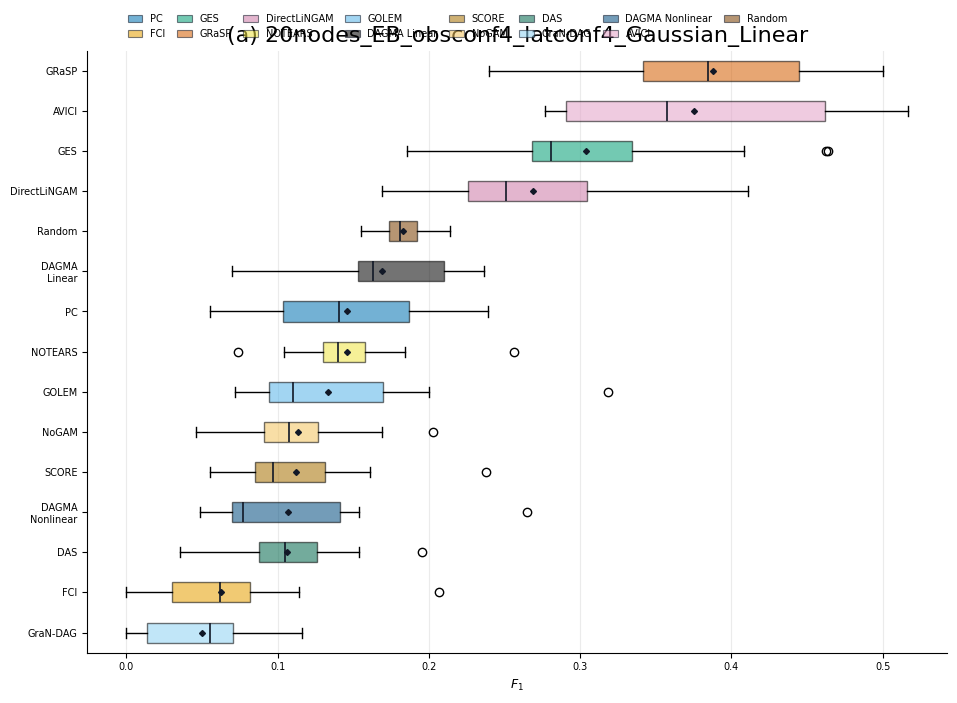

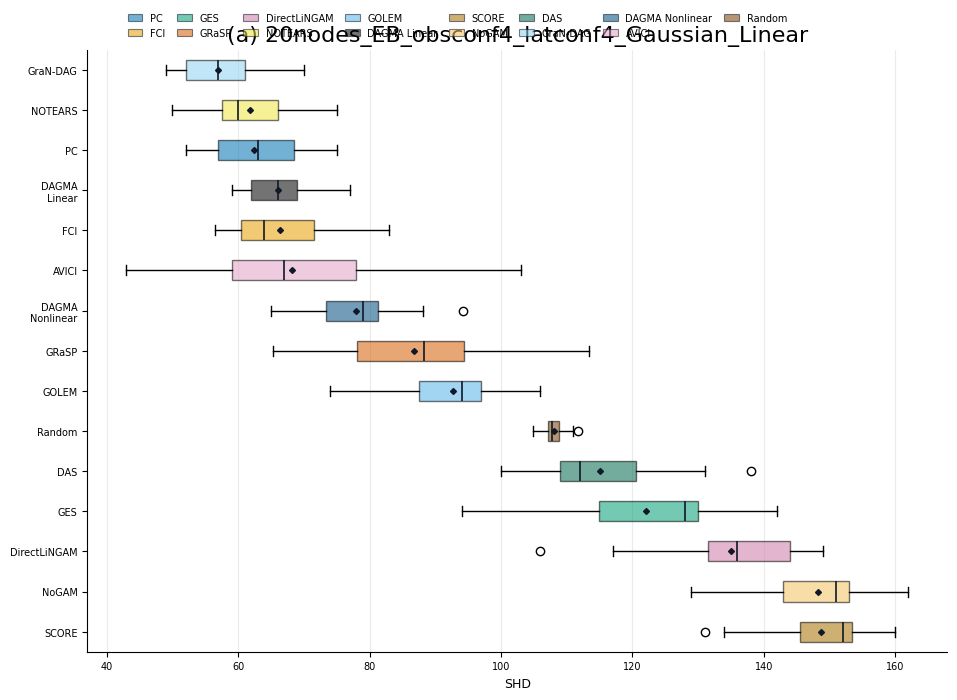

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.071894
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.245064
9,13,GraNDAG,0.000000


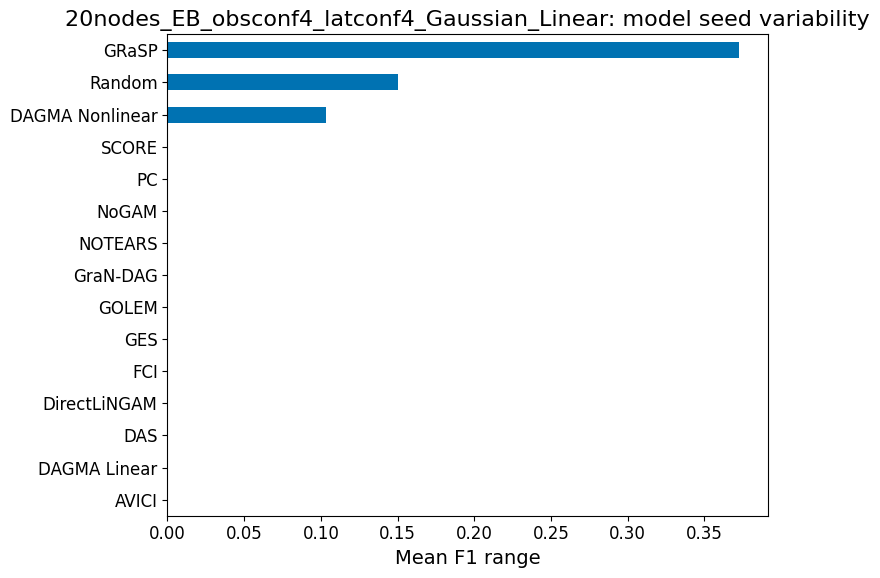

,model_seed,model,f1_range
0,0,AVICI,0.240258
1,0,DAGMA_Linear,0.166596
2,0,DAGMA_Nonlinear,0.190092
3,0,DAS,0.159899
4,0,DirectLiNGAM,0.241700
5,0,FCI,0.206897
6,0,GES,0.278552
7,0,GOLEM,0.246399
8,0,GRaSP,0.523646
9,0,GraNDAG,0.115942


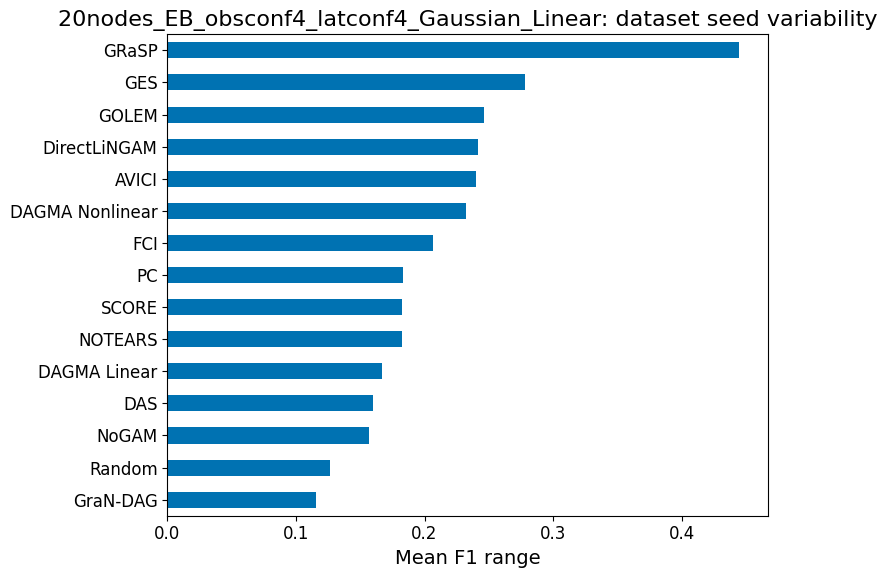

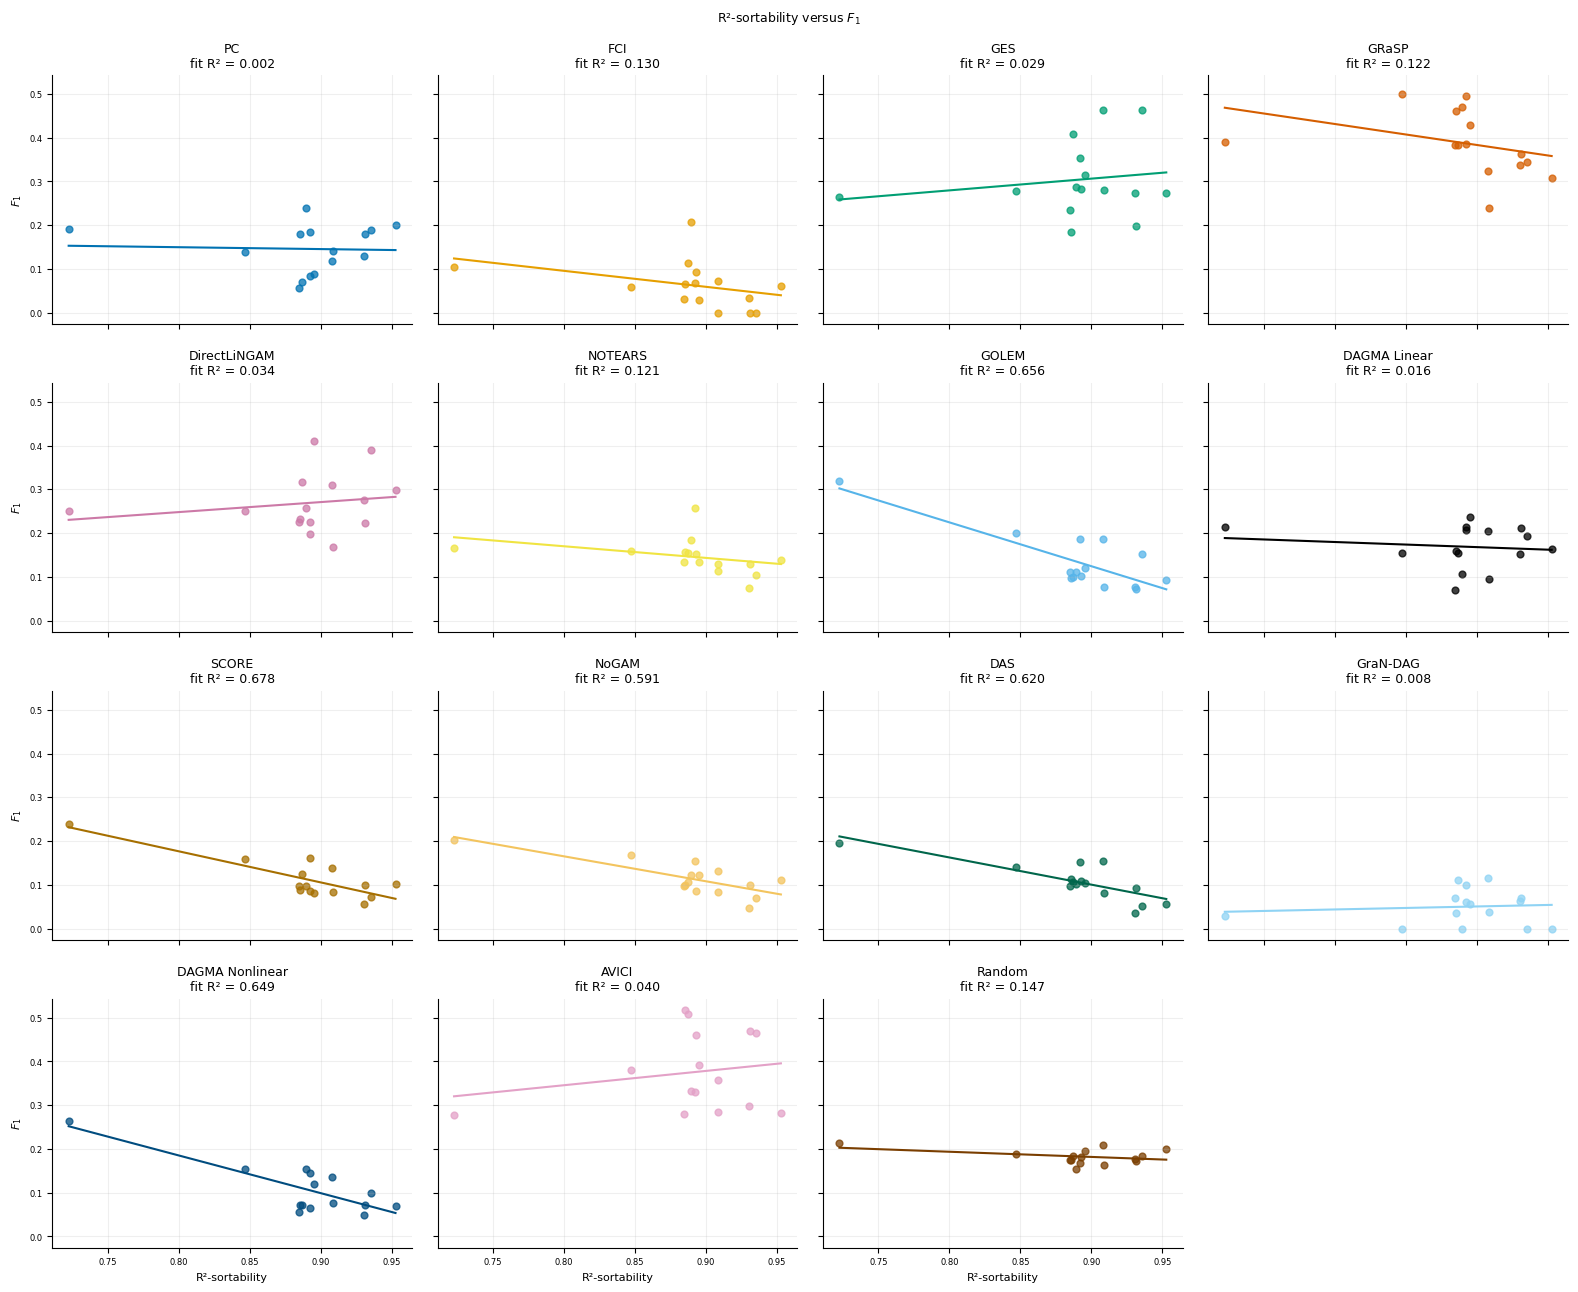

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,AVICI,0.298246,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
1,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAGMA_Linear,0.151899,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
2,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAGMA_Nonlinear,0.048664,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
3,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAS,0.035503,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
4,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DirectLiNGAM,0.275229,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
5,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,FCI,0.032787,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
6,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GES,0.273585,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
7,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GOLEM,0.077519,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
8,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GRaSP,0.338786,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
9,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GraNDAG,0.062500,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.977049,0.908197,305,298,0,277,0,20,2000
1,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
2,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.987097,0.935484,155,153,0,145,0,20,2000
3,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.970149,0.847015,268,260,0,227,0,20,2000
4,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.988701,0.887006,177,175,0,157,0,20,2000
5,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.961702,0.889362,235,226,0,209,0,20,2000
6,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.995413,0.931193,218,217,0,203,0,20,2000
7,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,1.000000,0.952727,275,275,0,262,0,20,2000
8,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.981928,0.885542,166,163,0,147,0,20,2000
9,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.986900,0.895197,229,226,0,205,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.199266,0.039707,0.327179,0.083895,0.476471,0.096429,0.732453
1,DAGMA_Linear,15,-0.126416,0.015981,-0.116752,0.273123,0.653474,0.114286,0.685066
2,DAGMA_Nonlinear,15,-0.805408,0.648682,-0.861780,0.874577,0.000290,-0.410714,0.128329
3,DAS,15,-0.787217,0.619711,-0.621425,0.659580,0.000495,-0.696429,0.003921
4,DirectLiNGAM,15,0.183222,0.033570,0.228736,0.065109,0.513356,0.196429,0.482899
5,FCI,15,-0.360973,0.130301,-0.365300,0.387993,0.186216,-0.476706,0.072398
6,GES,15,0.170486,0.029066,0.268704,0.064729,0.543531,0.207143,0.458843
7,GOLEM,15,-0.810227,0.656468,-1.002187,1.026351,0.000250,-0.525000,0.044484
8,GRaSP,15,-0.348882,0.121719,-0.479591,0.815143,0.202486,-0.685714,0.004772
9,GraNDAG,15,0.091335,0.008342,0.068577,-0.011273,0.746144,-0.009018,0.974556


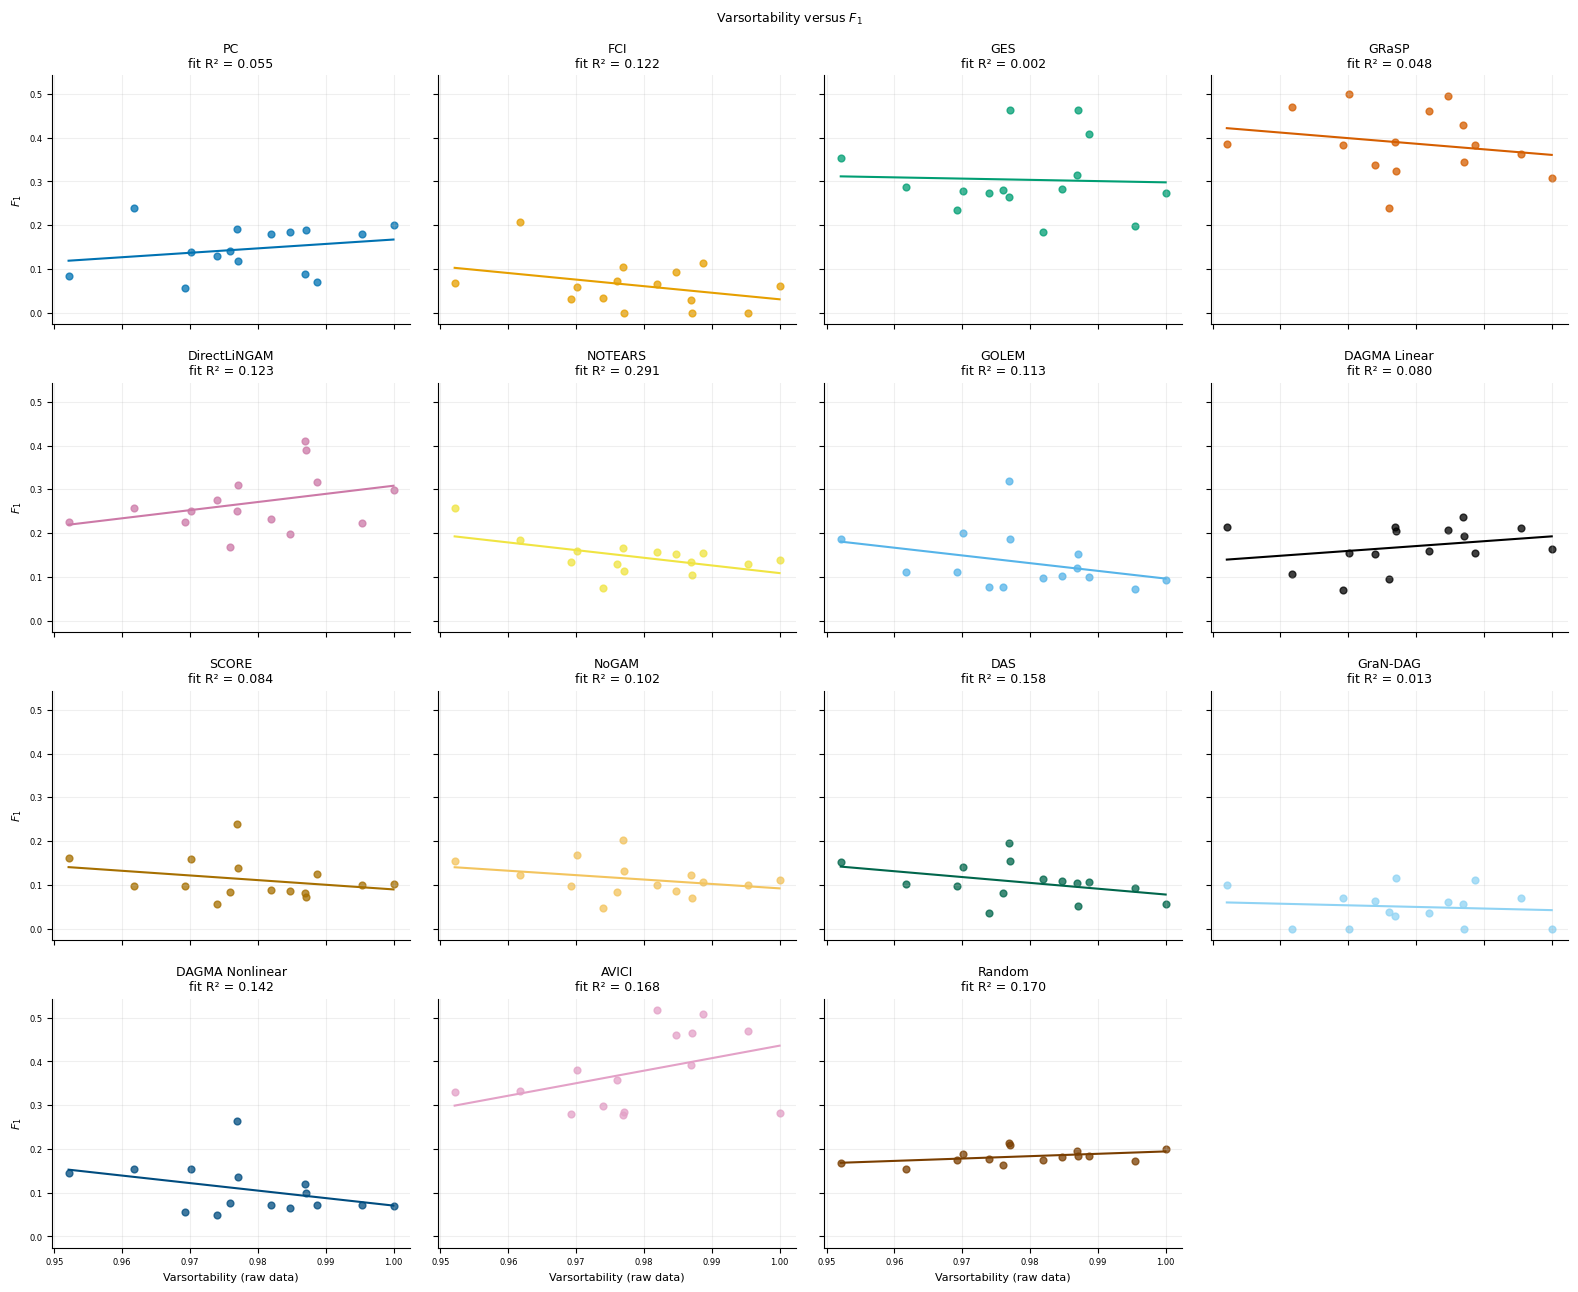

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,AVICI,0.298246,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
1,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAGMA_Linear,0.151899,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
2,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAGMA_Nonlinear,0.048664,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
3,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAS,0.035503,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
4,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DirectLiNGAM,0.275229,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
5,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,FCI,0.032787,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
6,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GES,0.273585,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
7,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GOLEM,0.077519,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
8,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GRaSP,0.338786,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
9,13,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GraNDAG,0.062500,15,20,EB,4,4,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.977049,0.908197,305,298,0,277,0,20,2000
1,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.973913,0.930435,345,336,0,321,0,20,2000
2,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.987097,0.935484,155,153,0,145,0,20,2000
3,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.970149,0.847015,268,260,0,227,0,20,2000
4,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.988701,0.887006,177,175,0,157,0,20,2000
5,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.961702,0.889362,235,226,0,209,0,20,2000
6,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.995413,0.931193,218,217,0,203,0,20,2000
7,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,1.000000,0.952727,275,275,0,262,0,20,2000
8,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.981928,0.885542,166,163,0,147,0,20,2000
9,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf4_latconf...,0.986900,0.895197,229,226,0,205,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.409864,0.167989,2.860929,-2.424853,0.129199,0.435714,0.104493
1,DAGMA_Linear,15,0.282315,0.079702,1.108429,-0.915794,0.307977,0.317857,0.248291
2,DAGMA_Nonlinear,15,-0.376939,0.142083,-1.714610,1.785076,0.166066,-0.325000,0.237225
3,DAS,15,-0.397022,0.157626,-1.332363,1.410066,0.142842,-0.278571,0.314709
4,DirectLiNGAM,15,0.350532,0.122873,1.860373,-1.552014,0.200214,0.325000,0.237225
5,FCI,15,-0.348941,0.121760,-1.501211,1.531916,0.202405,-0.268819,0.332644
6,GES,15,-0.042636,0.001818,-0.285676,0.583720,0.880078,-0.017857,0.949635
7,GOLEM,15,-0.335494,0.112556,-1.764166,1.860272,0.221534,-0.400000,0.139595
8,GRaSP,15,-0.218242,0.047629,-1.275390,1.636221,0.434563,-0.275000,0.321211
9,GraNDAG,15,-0.114959,0.013215,-0.366942,0.408975,0.683300,-0.028856,0.918690


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf4_latconf4_Gaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,AVICI,r2_sortability,15,0.096429,0.732453,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,0.114286,0.685066,estimated,1.000000
2,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.410714,0.128329,estimated,1.000000
3,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DAS,r2_sortability,15,-0.696429,0.003921,estimated,0.058818
4,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.196429,0.482899,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,FCI,r2_sortability,15,-0.476706,0.072398,estimated,0.651584
6,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GES,r2_sortability,15,0.207143,0.458843,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GOLEM,r2_sortability,15,-0.525000,0.044484,estimated,0.533807
8,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GRaSP,r2_sortability,15,-0.685714,0.004772,estimated,0.065351
9,benchmark,untuned,20nodes_EB_obsconf4_latconf4_Gaussian_Linear,GraNDAG,r2_sortability,15,-0.009018,0.974556,estimated,1.000000
